# Global Solution | Segurança pública inteligente em São Paulo
## Classificação de ocorrências com MLP
**Aluno:** Matheus Moura da Silva  
**RM:** 566782  
**Turma:** 2CCPR

Objetivo: classificar um registro como **furto simples (0)** ou **roubo (1)**, comparando três MLPs. A rede estima a classe de uma ocorrência existente ou hipotética; **não prevê ocorrência de crimes nem risco de bairros**.

Este notebook contém código de treinamento, resultados obtidos, gráficos e interpretação. Para executar: instalar `requirements.txt`, abrir este arquivo na raiz do projeto e executar todas as células. O treino leva poucos segundos neste recorte; o tempo varia conforme o computador.

## 1. Fonte, procedência e recorte
- Portal oficial: https://www.ssp.sp.gov.br/estatistica/consultas
- Distribuição histórica utilizada: https://github.com/nublia/data-science-playground
- Arquivo: https://raw.githubusercontent.com/nublia/data-science-playground/master/dat/boletins_ocorrencia_sp_clean_2016.csv.gz
- Documentação do distribuidor: https://github.com/nublia/data-science-playground/blob/master/nb/boletins_ocorrencia.ipynb

A fonte utilizada é um **espelho histórico de microdados atribuídos à SSP-SP**, distribuídos via data.world. Não foi um download direto do portal atual. Registramos o hash SHA-256 dos bytes e a data de acesso. O arquivo contém registros de 2016 (`ANO`), não uma base atualizada de 2026. O período foi escolhido por disponibilidade pública e dimensão adequada.

O dicionário do notebook de origem menciona campos de data/hora que **não existem no CSV limpo**. A inspeção do arquivo prevalece: não inventamos dia da semana ou período do dia. `MES` é o **mês de registro**, explicitamente identificado no formulário.

### Geografia do fato
Usamos `NOME_DEPARTAMENTO_CIRC = DECAP` (circunscrição do fato na capital), além de `CIDADE = S.PAULO`. O dicionário secundário chama CIDADE de município do registro; por isso **CIDADE isoladamente não fundamenta o recorte**. Não usamos `NOME_DEPARTAMENTO` ou `DELEGACIA` de elaboração para inferir o local do crime. DECAP corresponde ao Departamento de Polícia Judiciária da Capital: https://policiacivil.sp.gov.br/portal/faces/pages_home/institucional/departamentosOrgaos . A validade territorial depende do preenchimento correto da circunscrição na base histórica; não fizemos auditoria por limites geográficos.

### Rótulos e exclusões
Selecionamos exatamente `Furto (art. 155)` e `Roubo (art. 157)`, apenas consumados (`FLAG_STATUS = C`). Furtos qualificados, atos infracionais, tentativas e demais naturezas ficam fora do escopo. Antes dos filtros, removemos BOs com mais de uma rubrica ou valores conflitantes em distrito, mês, cidade ou departamento de circunscrição. Depois deduplicamos por `(ANO_BO, ID_DELEGACIA, NUM_BO)`, evitando múltiplas linhas do mesmo boletim. Essa chave operacional pode não identificar todos os boletins complementares; essa é uma limitação.

O script `preparar_dados.py` reproduz o download, confere o hash, executa os filtros e gera a amostra. Para refazer desde os bytes originais: `python preparar_dados.py`. O CSV da amostra já está incluído e contém somente hash do BO, distrito, mês e classe, sem nomes, endereços, placas ou características de pessoas.

In [1]:
from pathlib import Path
import json
import pandas as pd
ROOT = Path.cwd()
if not (ROOT / 'data/amostra.csv').exists():
    ROOT = ROOT / 'projeto'
proveniencia = json.loads((ROOT/'data/proveniencia.json').read_text())
print(json.dumps(proveniencia, indent=2, ensure_ascii=False))
dados = pd.read_csv(ROOT/'data/amostra.csv', dtype={'mes_registro':str})
print('\nAmostra:')
print(dados.head().to_string(index=False))
print('\nClasses (0=furto, 1=roubo):')
print(dados.rotulo.value_counts().sort_index().to_string())
print('\nAusentes:')
print(dados.isna().sum().to_string())
print('\nDistritos:', dados.distrito.nunique(), '| Meses:', dados.mes_registro.nunique())
assert dados.bo_hash.is_unique


{
  "linhas_fonte": 770371,
  "sha256": "fcad92a9f348b59b9c7a5b195d1fb956f8fb75eb9a5e55f84665d0bb7c0de70d",
  "url": "https://raw.githubusercontent.com/nublia/data-science-playground/master/dat/boletins_ocorrencia_sp_clean_2016.csv.gz",
  "acesso": "2026-11-10",
  "linhas_BO_inconsistente": 12920,
  "linhas_capital_consistentes": 500157,
  "linhas_elegiveis": 406585,
  "BOs_elegiveis": 404108,
  "classes_populacao": {
    "0": 202374,
    "1": 201734
  },
  "amostra": 20000,
  "classes_amostra": {
    "0": 10016,
    "1": 9984
  }
}

Amostra:
                 bo_hash                      distrito mes_registro  rotulo
0005a9d8113c7fb28219dd2a 17º D.P.  DOUTOR ALDO GALIANO           10       1
000850cacd6d83a080e4ff05               46º D.P.  PERUS            2       0
000c68315047d466d0c3cc59      57º D.P. PARQUE DA MOOCA            7       0
001bd3b03d96ac5064e5cd1f       03º D.P. CAMPOS ELISEOS            8       1
001c18dd608b45a1f89c391f           35º D.P.  JABAQUARA            6    

## 2. Escolha dos atributos e preparação
| Campo | Papel | Justificativa / transformação |
|---|---|---|
| `NOME_DELEGACIA_CIRC` → `distrito` | Entrada categórica | Contexto territorial do **fato**. One-hot, sem ordem numérica artificial. Não é a delegacia de registro. |
| `MES` → `mes_registro` | Entrada categórica | Sazonalidade e contexto do registro em 2016. One-hot de 12 meses; não é o mês comprovado do fato. |
| `RUBRICA` → `rotulo` | Alvo | 0 = furto simples; 1 = roubo. Nunca integra as entradas. |
| Hash de ano/delegacia/número do BO | Auditoria | Só verifica unicidade e separação; nunca entra na rede. |

Excluímos `DESDOBRAMENTO`, `CONDUTA`, natureza, solução e outros campos jurídicos para evitar pistas diretas ou derivadas do rótulo. Também excluímos dados de pessoas e localização de endereço. Não usamos coordenadas precisas.

Espaços são removidos nos textos. Valores ausentes de distrito seriam substituídos por `NAO INFORMADO`; mês ausente viraria categoria `0`, mas não há tais ausências na amostra. Não há atributos numéricos contínuos: **não se aplica StandardScaler**. One-hot produz apenas valores 0/1, com `handle_unknown=ignore`; a aplicação restringe as entradas às categorias do treino.

Selecionamos 20.000 BOs por amostragem estratificada proporcional, sem balanceamento artificial, semente 42. Após a deduplicação, dividimos em **14.000 treino, 3.000 validação e 3.000 teste**, estratificados. O encoder é ajustado apenas no treino. Não fazemos busca de hiperparâmetros ou seleção de limiar no teste. A divisão aleatória avalia generalização dentro do mesmo período; não mede generalização temporal.

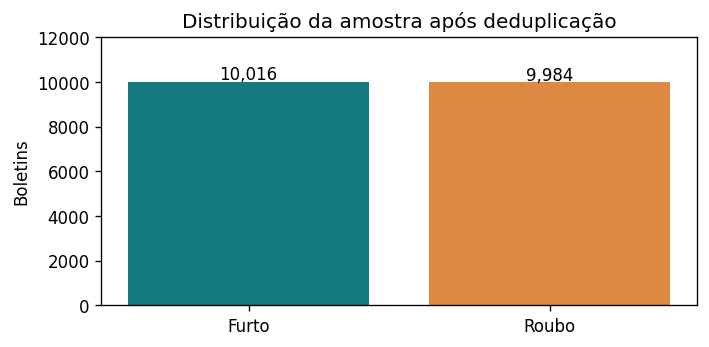

In [2]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6,3))
contagens = dados.rotulo.value_counts().sort_index()
ax.bar(['Furto','Roubo'], contagens.values, color=['#137b80','#dd8942'])
ax.set_title('Distribuição da amostra após deduplicação')
ax.set_ylabel('Boletins')
for i,n in enumerate(contagens.values): ax.text(i,n+100,f'{n:,}',ha='center')
ax.set_ylim(0,12000)
plt.tight_layout()
plt.show()


## 3. Arquiteturas e treinamento
Todas as redes têm entrada one-hot, camadas densas ocultas com **ReLU** e uma saída **sigmoid**. Para cada camada: `h = ReLU(XW+b)`; a saída é `p(roubo)=sigmoid(hW+b)`. A estimativa de furto é `1-p(roubo)`, e o limiar foi fixado em 0,5.

Usamos `MLPClassifier` do scikit-learn: é uma MLP densa real, treinada por retropropagação e Adam. A disciplina contém CNN no nome, mas o enunciado exige **MLP para dados tabulares**, não uma CNN.

| Experimento | Camadas ocultas | Taxa de aprendizado | Alpha L2 | Hipótese |
|---|---|---|---|---|
| A | 16 | 0,001 | 0,0001 | Rede pequena como referência; menor capacidade de memorizar. |
| B | 64 → 32 | 0,001 | 0,0001 | Testar se mais capacidade e profundidade melhoram as interações. |
| C | 128 → 64 → 32 | 0,0005 | 0,01 | Testar maior profundidade com regularização mais forte e passos menores. |

Perda: **entropia cruzada binária** com penalidade L2 nos pesos. Otimizador: Adam (betas padrão 0,9 e 0,999; epsilon 1e-8); batch size 128; semente 42; embaralhamento a cada época; máximo 100 épocas. `partial_fit` preserva os estados de Adam entre épocas. Parada antecipada na **validação externa**, paciência 12; salvar pesos quando F1 macro aumentar mais de 0,0001. As curvas abaixo mostram a entropia cruzada preditiva **sem a parcela L2**, calculada separadamente para comparar treino e validação.

A configuração C altera múltiplos fatores ao mesmo tempo; esse desenho compara configurações, mas não permite atribuir causalmente o resultado apenas à regularização.

### Métricas e critério fixados antes do teste
Acurácia é a proporção de acertos. Precision de roubo = TP/(TP+FP); recall de roubo = TP/(TP+FN); F1 de roubo é a média harmônica dessas duas medidas. O **F1 macro** é a média dos F1 das duas classes e é usado para selecionar a arquitetura e a época. O teste é acessado apenas após congelar rede, pesos e limiar; não reentreinamos com treino+validação antes de entregar.

In [3]:
"""Três MLPs, seleção em validação externa e uma avaliação final em teste."""
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
os.environ.setdefault('OMP_NUM_THREADS','1')
from pathlib import Path
import copy,json,pickle,time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,log_loss,confusion_matrix,classification_report
from threadpoolctl import threadpool_limits
ROOT=globals().get('ROOT', Path.cwd())
FEATURES=['distrito','mes_registro']
CONFIGS=[dict(nome='A • compacta',hidden=(16,),alpha=0.0001,lr=0.001),dict(nome='B • intermediária',hidden=(64,32),alpha=0.0001,lr=0.001),dict(nome='C • regularizada',hidden=(128,64,32),alpha=0.01,lr=0.0005)]
def metricas(y,p):
    h=(np.asarray(p)>=0.5).astype(int)
    return dict(acuracia=accuracy_score(y,h),precision=precision_score(y,h,zero_division=0),recall=recall_score(y,h,zero_division=0),f1=f1_score(y,h,zero_division=0),f1_macro=f1_score(y,h,average='macro',zero_division=0),perda=log_loss(y,p,labels=[0,1]))
def executar():
    d=pd.read_csv(ROOT/'data/amostra.csv',dtype={'mes_registro':str})
    tr,rest=train_test_split(np.arange(len(d)),test_size=0.3,stratify=d.rotulo,random_state=42)
    va,te=train_test_split(rest,test_size=0.5,stratify=d.rotulo.iloc[rest],random_state=42)
    assert not(set(tr)&set(va) or set(tr)&set(te) or set(va)&set(te))
    assert d.bo_hash.is_unique
    enc=OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float64)
    Xtr=enc.fit_transform(d.iloc[tr][FEATURES]);Xva=enc.transform(d.iloc[va][FEATURES])
    ytr=d.rotulo.iloc[tr].to_numpy();yva=d.rotulo.iloc[va].to_numpy()
    results=[];models=[];histories=[]
    for cfg in CONFIGS:
        m=MLPClassifier(hidden_layer_sizes=cfg['hidden'],activation='relu',solver='adam',alpha=cfg['alpha'],batch_size=128,learning_rate_init=cfg['lr'],random_state=42,shuffle=True,max_iter=1,early_stopping=False)
        best=-1;wait=0;history=[];start=time.time()
        with threadpool_limits(limits=1):
            for epoch in range(1,101):
                m.partial_fit(Xtr,ytr,classes=np.array([0,1]))
                mt=metricas(ytr,m.predict_proba(Xtr)[:,1]);mv=metricas(yva,m.predict_proba(Xva)[:,1])
                history.append(dict(epoca=epoch,treino=mt,validacao=mv))
                if mv['f1_macro']>best+0.0001:
                    best=mv['f1_macro'];chosen=copy.deepcopy(m);best_epoch=epoch;wait=0
                else:wait+=1
                if wait>=12:break
        row=dict(nome=cfg['nome'],hidden=list(cfg['hidden']),alpha=cfg['alpha'],lr=cfg['lr'],epocas=len(history),melhor_epoca=best_epoch,parametros=sum(w.size for w in chosen.coefs_)+sum(b.size for b in chosen.intercepts_),segundos=round(time.time()-start,2),**metricas(yva,chosen.predict_proba(Xva)[:,1]))
        results.append(row);models.append(chosen);histories.append(history)
        print(json.dumps(row,ensure_ascii=False),flush=True)
    winner=max(range(3),key=lambda i:results[i]['f1_macro']);m=models[winner]
    # O teste é acessado só depois de congelar arquitetura, pesos e limiar.
    Xte=enc.transform(d.iloc[te][FEATURES]);yte=d.rotulo.iloc[te].to_numpy();p=m.predict_proba(Xte)[:,1]
    majority=int(pd.Series(ytr).mode().iloc[0]);base=metricas(yte,np.repeat(majority,len(yte)))
    info=dict(arquiteturas=results,vencedor=winner,nome=results[winner]['nome'],dimensao_entrada=Xtr.shape[1],divisao={'treino':len(tr),'validacao':len(va),'teste':len(te)},distribuicao={k:d.iloc[v].rotulo.value_counts().sort_index().to_dict() for k,v in [('treino',tr),('validacao',va),('teste',te)]},teste=metricas(yte,p),baseline_teste=base,matriz=confusion_matrix(yte,p>=0.5).tolist(),relatorio=classification_report(yte,p>=0.5,target_names=['Furto','Roubo'],output_dict=True,zero_division=0),historicos=histories)
    art=ROOT/'artifacts';art.mkdir(exist_ok=True)
    (art/'resultados.json').write_text(json.dumps(info,ensure_ascii=False,indent=2))
    pd.DataFrame(results).to_csv(art/'comparacao.csv',index=False)
    with open(art/'modelo.pkl','wb') as f:pickle.dump({'encoder':enc,'modelo':m,'features':FEATURES},f)
    splits=d[['bo_hash']].copy();splits['conjunto']='';
    for ids,name in [(tr,'treino'),(va,'validacao'),(te,'teste')]:splits.loc[ids,'conjunto']=name
    splits.to_csv(art/'divisao.csv',index=False)
    export=dict(features=FEATURES,categories=[list(x) for x in enc.categories_],weights=[x.tolist() for x in m.coefs_],biases=[x.tolist() for x in m.intercepts_],classes=['Furto','Roubo'],threshold=0.5,metadata={k:v for k,v in info.items() if k not in ['historicos','relatorio']})
    (ROOT/'dist/modelo.json').write_text(json.dumps(export,ensure_ascii=False))
    h=histories[winner];plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
    fig,axs=plt.subplots(1,2,figsize=(11,3.7))
    for ax,key,title in [(axs[0],'acuracia','Acurácia'),(axs[1],'perda','Entropia cruzada')]:
        for part,label,color in [('treino','Treino','#146b82'),('validacao','Validação','#dd8942')]:ax.plot([x['epoca'] for x in h],[x[part][key] for x in h],label=label,color=color,lw=2)
        ax.axvline(results[winner]['melhor_epoca'],color='#909090',ls=':',label='Pesos escolhidos');ax.set(xlabel='Época',title=title);ax.legend(fontsize=8);ax.grid(alpha=.15)
    fig.tight_layout();fig.savefig(art/'curvas.png',dpi=180);plt.close(fig)
    cm=np.array(info['matriz']);fig,ax=plt.subplots(figsize=(4.6,3.5));ax.imshow(cm,cmap='Blues',vmin=0,vmax=cm.max())
    for i in range(2):
        for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=20,color='white' if cm[i,j]>cm.max()*0.75 else '#172c40')
    ax.set(xticks=[0,1],xticklabels=['Furto','Roubo'],yticks=[0,1],yticklabels=['Furto','Roubo'],xlabel='Classe estimada',ylabel='Classe real',title='Matriz de confusão • teste final');fig.tight_layout();fig.savefig(art/'matriz.png',dpi=180);plt.close(fig)
    print('FINAL',json.dumps({k:info[k] for k in ['nome','dimensao_entrada','divisao','teste','baseline_teste','matriz']},ensure_ascii=False),flush=True)
    return info


In [4]:
resultados = executar()
print('\nComparação em VALIDAÇÃO:')
print(pd.DataFrame(resultados['arquiteturas'])[['nome','hidden','parametros','melhor_epoca','epocas','acuracia','precision','recall','f1','f1_macro']].to_string(index=False))
print('\nDistribuição por conjunto:')
print(json.dumps(resultados['distribuicao'],indent=2))


{"nome": "A • compacta", "hidden": [16], "alpha": 0.0001, "lr": 0.001, "epocas": 18, "melhor_epoca": 6, "parametros": 1713, "segundos": 0.67, "acuracia": 0.632, "precision": 0.6228179551122195, "recall": 0.6668891855807744, "f1": 0.6441005802707931, "f1_macro": 0.6315740996592061, "perda": 0.6506515563065749}
{"nome": "B • intermediária", "hidden": [64, 32], "alpha": 0.0001, "lr": 0.001, "epocas": 15, "melhor_epoca": 3, "parametros": 8897, "segundos": 1.06, "acuracia": 0.6286666666666667, "precision": 0.6194029850746269, "recall": 0.664886515353805, "f1": 0.6413393432066967, "f1_macro": 0.6282024981410125, "perda": 0.6501040803241978}
{"nome": "C • regularizada", "hidden": [128, 64, 32], "alpha": 0.01, "lr": 0.0005, "epocas": 15, "melhor_epoca": 3, "parametros": 23937, "segundos": 2.08, "acuracia": 0.624, "precision": 0.6198186528497409, "recall": 0.6388518024032043, "f1": 0.6291913214990138, "f1_macro": 0.6239262895527523, "perda": 0.6499364113646631}
FINAL {"nome": "A • compacta", "d

## 4. Resultados e seleção
A rede **A (16 neurônios)** foi selecionada pelo maior F1 macro de validação: **0,6316**, contra 0,6282 (B) e 0,6239 (C). Os melhores pesos foram obtidos na época **6**, com interrupção após a época 18. A diferença é pequena e foi medida com uma única semente; não há evidência de superioridade estatística. Preferimos a rede compacta também pela simplicidade, mas o critério efetivo foi o F1 macro.

Com 105 entradas, A possui **1.713 parâmetros**: 105×16+16+16×1+1. B possui 8.897 e C possui 23.937. O aumento de capacidade não trouxe ganho neste recorte. As duas variáveis disponíveis oferecem sinal limitado.

In [5]:
print('Modelo congelado:', resultados['nome'])
print('\nTESTE FINAL:')
print(json.dumps(resultados['teste'],indent=2))
print('\nRelatório por classe:')
print(pd.DataFrame(resultados['relatorio']).T.to_string())
print('\nBaseline majoritária:')
print(json.dumps(resultados['baseline_teste'],indent=2))
print('\nMatriz (linhas=reais; colunas=estimadas; ordem=furto, roubo):')
print(resultados['matriz'])


Modelo congelado: A • compacta

TESTE FINAL:
{
  "acuracia": 0.6276666666666667,
  "precision": 0.6194968553459119,
  "recall": 0.6579826319305278,
  "f1": 0.638160025915128,
  "f1_macro": 0.6273532707673821,
  "perda": 0.651040286947056
}

Relatório por classe:
              precision    recall  f1-score      support
Furto          0.636879  0.597472  0.616547  1503.000000
Roubo          0.619497  0.657983  0.638160  1497.000000
accuracy       0.627667  0.627667  0.627667     0.627667
macro avg      0.628188  0.627727  0.627353  3000.000000
weighted avg   0.628206  0.627667  0.627332  3000.000000

Baseline majoritária:
{
  "acuracia": 0.501,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "f1_macro": 0.33377748167888077,
  "perda": 17.98578304116946
}

Matriz (linhas=reais; colunas=estimadas; ordem=furto, roubo):
[[898, 605], [512, 985]]


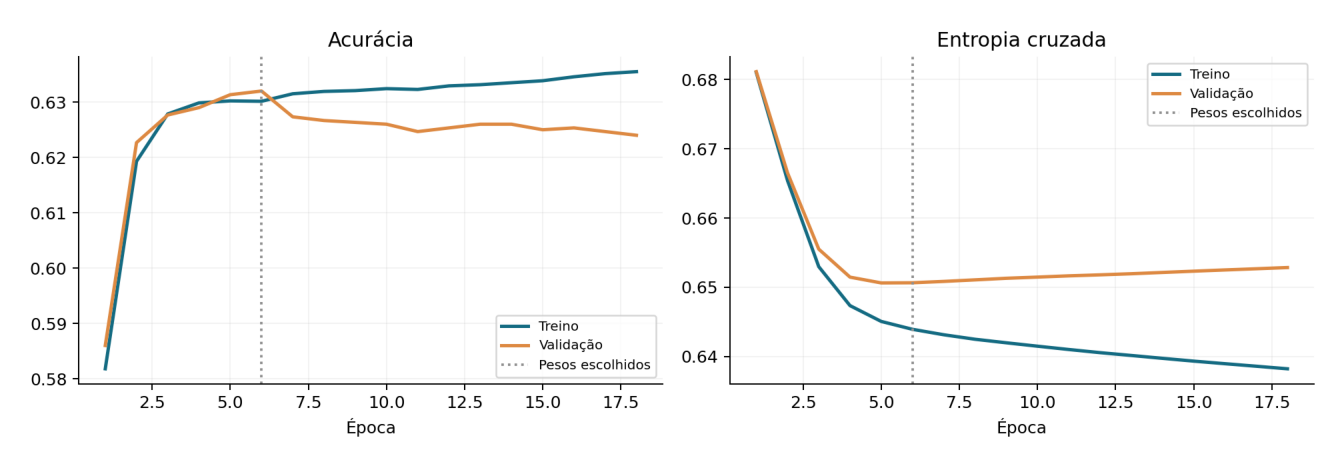

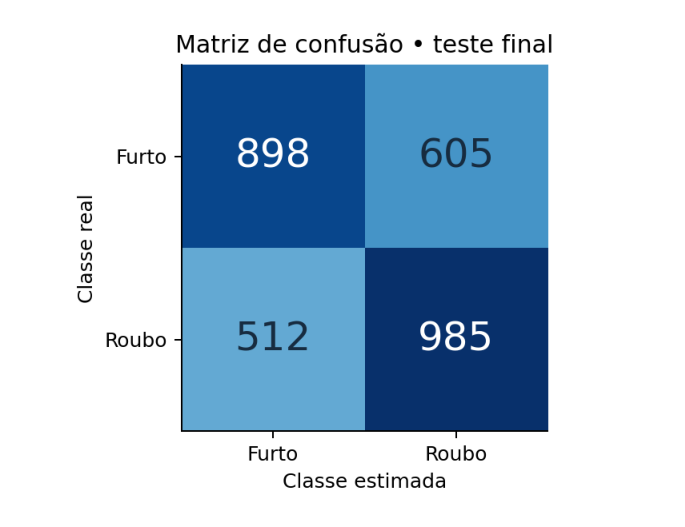

In [6]:
fig, ax = plt.subplots(figsize=(12,4))
ax.imshow(plt.imread(ROOT/'artifacts/curvas.png')); ax.axis('off')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6,4.5))
ax.imshow(plt.imread(ROOT/'artifacts/matriz.png')); ax.axis('off')
plt.tight_layout(); plt.show()


## 5. Interpretação e diagnóstico
No teste final: **acurácia 62,77%; precision de roubo 61,95%; recall de roubo 65,80%; F1 de roubo 63,82%; F1 macro 62,74%**. A baseline que sempre prevê furto tem acurácia 50,10% e F1 macro 33,38%. O ganho de acurácia é de **12,67 pontos percentuais**. Esses valores não medem precisão jurídica nem risco de vitimização.

Matriz de confusão: **898 furtos** e **985 roubos** classificados corretamente; **605 furtos classificados como roubo** e **512 roubos classificados como furto**. Há 1.117 erros em 3.000 casos, uma limitação material.

Na época escolhida, a acurácia é 63,01% no treino e 63,20% na validação; perdas 0,6439 e 0,6507. Não há grande separação de acurácia. Após essa época, a perda de treino segue caindo enquanto a de validação aumenta levemente: **sinal de overfitting leve**, mitigado pela restauração dos pesos da época 6. Desempenho moderado em ambos os conjuntos também é compatível com baixa informação dos atributos ou viés do modelo; não se pode diagnosticar underfitting apenas por uma acurácia modesta.

Não ajustamos novos parâmetros após observar o teste. Como próximos passos, em outro experimento: dados recentes obtidos diretamente da SSP, variáveis do fato com dicionário auditado, validação temporal, múltiplas sementes, intervalos de confiança e calibração em um conjunto separado.

## 6. Aplicação web e equivalência de inferência
A interface em `dist/` carrega **os pesos reais da rede selecionada** e as categorias do encoder exportados em `modelo.json`. A multiplicação das matrizes, ReLU e sigmoid são executadas em JavaScript no navegador. Não há API externa nem respostas simuladas.

O formulário usa exatamente `distrito` e `mes_registro`, na mesma ordem do treino. Os percentuais somam 100%, mas não tiveram calibração validada e devem ser interpretados com cautela. A mensagem principal deixa claro que o modelo não estima se um crime vai acontecer.

Execute `python SERVIR_APP.py` e acesse http://localhost:8000 . A aplicação já está pública em https://ocorrencias-sp-mlp-lab.awakegerbil3.chatgpt.site/ e foi testada no navegador sem login. O formulário rejeitou distrito vazio; Sé/Janeiro resultou em furto 68,6% e roubo 31,4%; Capão Redondo/Dezembro resultou em roubo 66,0% e furto 34,0%. O README contém o endereço e os comandos para enviar o projeto ao GitHub.

In [7]:
import sys, subprocess
processo = subprocess.run([sys.executable, str(ROOT/'verificar.py')],capture_output=True,text=True,check=True)
print(processo.stdout)


{
  "boletins_unicos": 20000,
  "conjuntos_disjuntos": true,
  "casos_paridade": 200,
  "erro_maximo_python_js": 1.1102230246251565e-16,
  "probabilidades_validas": true
}



## 7. Limitações, ética e uso de IA generativa
- A base foi tratada por um distribuidor secundário; o hash garante identidade dos bytes usados, não autenticidade completa de toda a cadeia de origem. Não equivale a validação oficial da SSP.
- Registros de 2016 não representam o cenário atual. Não há denominador de população exposta, mobilidade ou subnotificação; portanto não se calcula risco criminal.
- O mês é do registro. A circunscrição depende da qualidade do cadastro histórico. A chave do BO não resolve necessariamente vínculos de boletins complementares.
- O recorte exclui furtos qualificados, tentativas e BOs com múltiplas rubricas, alterando a população representada.
- Atributos territoriais podem refletir desigualdades e práticas de registro. Não há atributos de raça, sexo, idade, nomes ou endereço de vítimas. Não usar o sistema para decisões policiais ou judiciais.
- Uma única amostra/semente e apenas três configurações não permitem conclusões universais. As probabilidades são saídas sigmoid sem calibração avaliada.

**Uso de IA:** ChatGPT apoiou a leitura do enunciado, programação do pipeline, exportação da inferência, documentação e redação do relatório. Os três modelos foram efetivamente treinados; tabelas e gráficos vêm dos resultados salvos. A responsabilidade pela revisão, compreensão, identificação dos integrantes e apresentação é da equipe. A equipe deve conseguir explicar one-hot, camadas densas, sigmoid, entropia cruzada, validação separada e matriz de confusão.

## 8. Materiais e conferência
- `preparar_dados.py`: aquisição e recorte reproduzíveis; hash em `data/proveniencia.json`.
- `treinar.py`: três MLPs, seleção externa e teste final.
- `artifacts/`: resultados, pesos, encoder, divisões, gráficos e verificação.
- `dist/`: aplicação estática com os pesos selecionados.
- `relatorio/relatorio_10_slides.pdf`: apresentação técnica limitada a 10 slides.
- `README.md`: execução, links, fonte e publicação GitHub Pages.

**Identificação:** Matheus Moura da Silva, RM 566782, turma 2CCPR.

**Antes da entrega:** enviar o pacote ao GitHub e entregar os materiais pelo portal da faculdade. O acesso público da aplicação já foi liberado e testado. A publicação na conta GitHub do aluno depende de autenticação dessa conta; o projeto não inventa um endereço de repositório.